<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_11/dataset_pbl/praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 3**
## **Langkah 1 - Import Library dan Buat Fungsi Plotting**

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## **Langkah 2 - Buat Data Dummy**

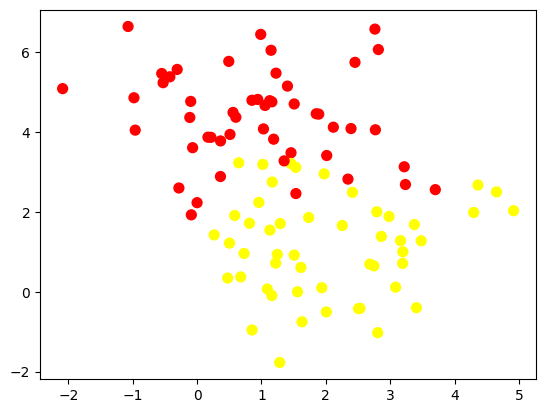

In [3]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

## **Langkah 3 - Analisis Dampak Tunning**
Untuk mengatasi hal ini, teknik penghalusan margin pada SVM dapat diterapkan. Teknik ini berfungsi untuk memasukkan beberapa titik data ke dalam margin supaya menghasilkan fitting yang lebih baik. Penebalan margin dari hasil teknik penghalusan dikelola oleh sebuah parameter tuning (dikenal sebagai C). Contoh dibawah menunjukkan perubahan pada C berdampak pada hasil fitting final.

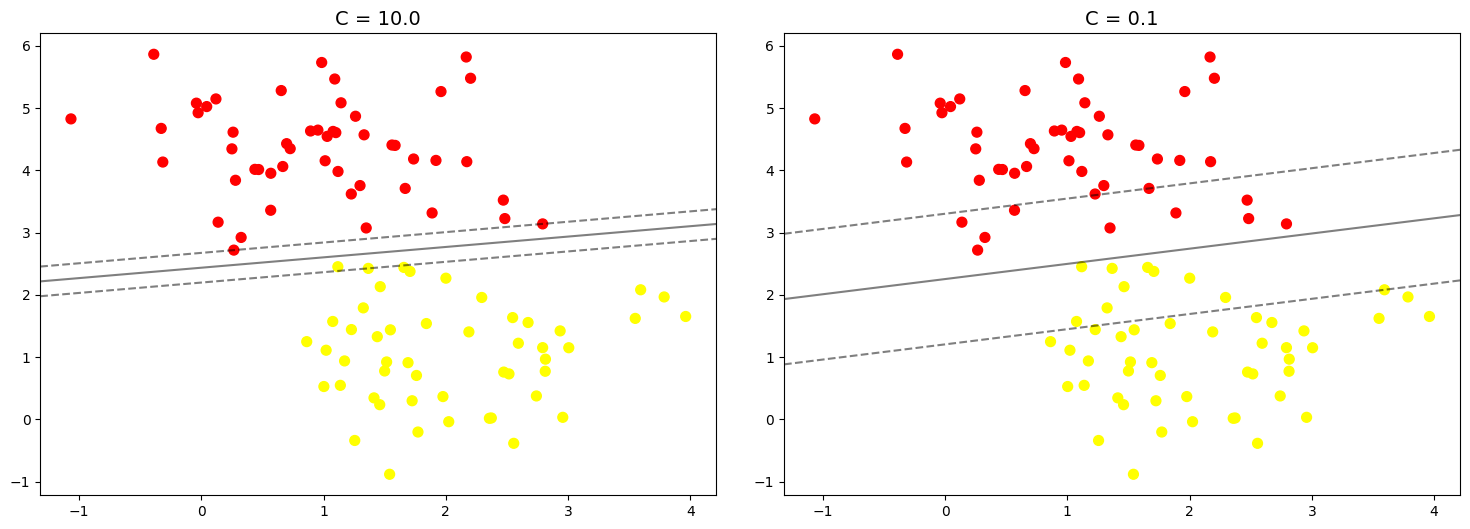

In [4]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

## **Penyesuaian Menggunakan Sleep Health and Lifestyle Dataset**

Di bawah ini kita akan memuat dataset `/content/Sleep_health_and_lifestyle_dataset.csv`. Kita akan memilih dua fitur numerik yang relevan untuk visualisasi 2D, serta melakukan klasifikasi biner berdasarkan variabel target (misalnya, memprediksi adanya Gangguan Tidur / *Sleep Disorder*).

In [5]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load dataset
df = pd.read_csv('/content/Sleep_health_and_lifestyle_dataset.csv')
display(df.head())
print(df.info())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB
None


### **Preprocessing & Feature Selection**
Untuk mempermudah visualisasi 2D seperti pada contoh praktikum, kita akan memilih dua fitur numerik:
1. `Sleep Duration` (Durasi Tidur)
2. `Physical Activity Level` (Tingkat Aktivitas Fisik)

Sebagai target, kita akan membuat klasifikasi biner: Apakah seseorang memiliki gangguan tidur (`Sleep Apnea` atau `Insomnia` disatukan sebagai `1`) atau normal (`None` sebagai `0`).

In [6]:
# Membuat target biner: 1 jika ada Gangguan Tidur (Sleep Apnea / Insomnia), 0 jika None
df['Has_Disorder'] = df['Sleep Disorder'].apply(lambda x: 0 if pd.isna(x) or x == 'None' else 1)

# Memilih 2 fitur numerik
features = ['Sleep Duration', 'Physical Activity Level']
X_sleep = df[features].values
y_sleep = df['Has_Disorder'].values

# Standarisasi fitur agar skala seimbang saat fitting SVM
scaler = StandardScaler()
X_sleep_scaled = scaler.fit_transform(X_sleep)

# Tampilkan jumlah masing-masing kelas
print("Distribusi target biner:")
print(df['Has_Disorder'].value_counts())

Distribusi target biner:
Has_Disorder
0    219
1    155
Name: count, dtype: int64


### **Visualisasi Data Dummy dari Dataset**
Sama seperti **Langkah 2**, kita visualisasikan sebaran data yang sudah kita pilih dari dataset baru.

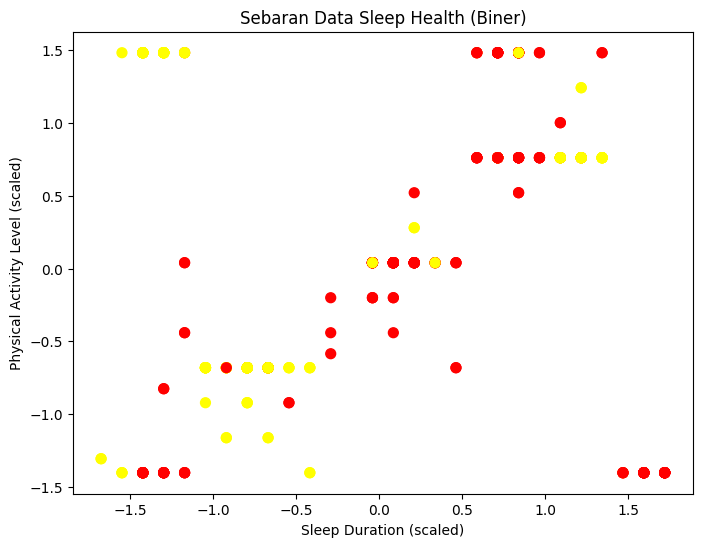

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(X_sleep_scaled[:, 0], X_sleep_scaled[:, 1], c=y_sleep, s=50, cmap='autumn')
plt.xlabel('Sleep Duration (scaled)')
plt.ylabel('Physical Activity Level (scaled)')
plt.title('Sebaran Data Sleep Health (Biner)')
plt.show()

### **Analisis Dampak Tuning C pada Dataset Baru**
Sekarang kita jalankan perbandingan dampak nilai tuning $C = 10.0$ dan $C = 0.1$ pada SVM linear menggunakan data sesungguhnya ini.

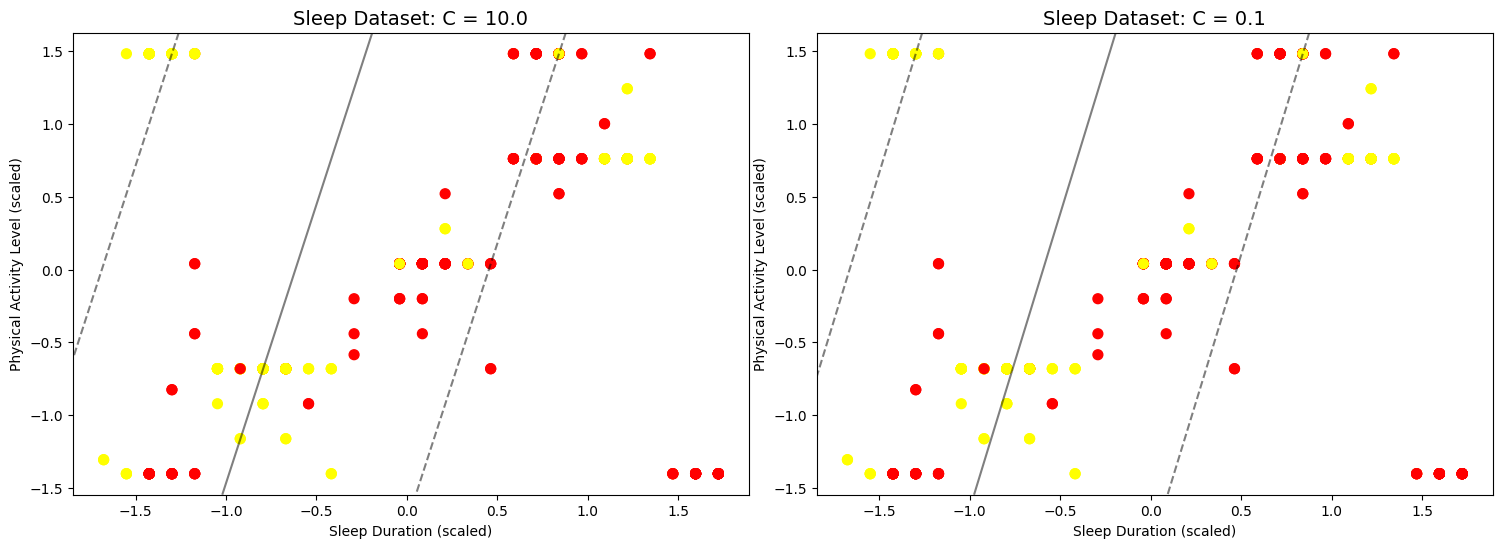

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model_sleep = SVC(kernel='linear', C=C).fit(X_sleep_scaled, y_sleep)

    # Plot titik data asli
    axi.scatter(X_sleep_scaled[:, 0], X_sleep_scaled[:, 1], c=y_sleep, s=50, cmap='autumn')

    # Plot decision boundary menggunakan fungsi yang sudah Anda buat di Langkah 1
    plot_svc_decision_function(model_sleep, axi)

    axi.set_xlabel('Sleep Duration (scaled)')
    axi.set_ylabel('Physical Activity Level (scaled)')
    axi.set_title(f'Sleep Dataset: C = {C}', size=14)